Installing Libraries

In [1]:
!pip install -q "gymnasium>=0.29" "stable-baselines3[extra]>=2.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 55.9 MB/s eta 0:00:00


Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env

SEED = 42

np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Project Configuration

In [3]:
# ============================================================
# FINAL PROJECT CONFIGURATION
# ============================================================
MAP_SIZE = 100.0
START = np.array([10.0, 10.0], dtype=np.float32)
GOAL = np.array([90.0, 90.0], dtype=np.float32)
USER = np.array([75.0, 65.0], dtype=np.float32)
MAX_STEPS = 160
MAX_SPEED = 2.5
MAX_POWER = 1.0
INITIAL_ENERGY = 100.0
MIN_SINR_DB = 5.0
ALTITUDE = 50.0
GOAL_TOLERANCE = 5.0

# No-fly zones: (x, y, radius)
OBSTACLES = [
    (35.0, 35.0, 10.0),
    (60.0, 55.0, 9.0),
    (55.0, 80.0, 8.0)
]

# Safe reference route used by the trajectory-fidelity term.
# The route bends around the no-fly zones.
REFERENCE_WAYPOINTS = np.array([
    [10.0, 10.0],
    [20.0, 20.0],
    [20.0, 55.0],
    [45.0, 55.0],
    [45.0, 70.0],
    [70.0, 70.0],
    [90.0, 90.0]
], dtype=np.float32)

print("Project configuration loaded.")


Project configuration loaded.


Visualize the UAV environment

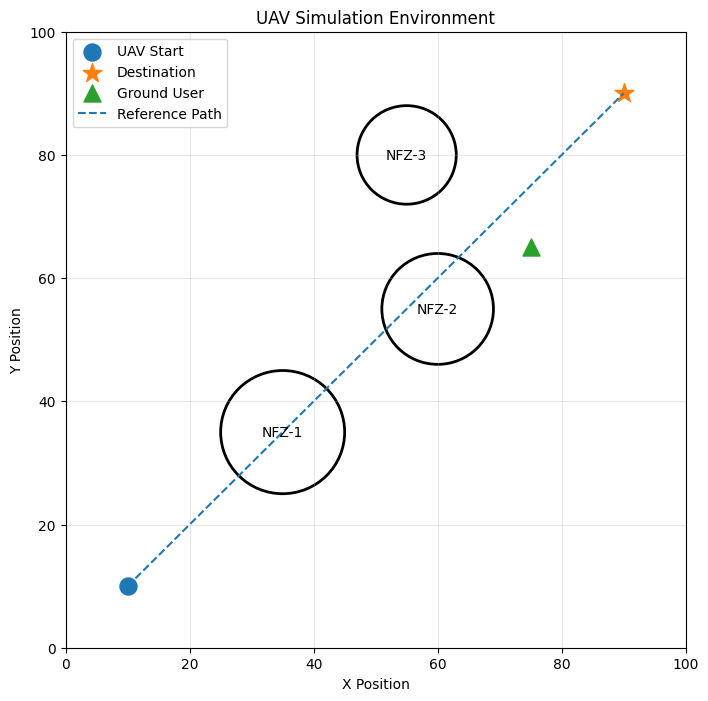

In [4]:
plt.figure(figsize=(8, 8))

# Start
plt.scatter(
    START[0],
    START[1],
    s=150,
    marker="o",
    label="UAV Start"
)

# Goal
plt.scatter(
    GOAL[0],
    GOAL[1],
    s=200,
    marker="*",
    label="Destination"
)

# Ground user
plt.scatter(
    USER[0],
    USER[1],
    s=150,
    marker="^",
    label="Ground User"
)

# No-fly zones
for i, (x, y, r) in enumerate(OBSTACLES):

    circle = plt.Circle(
        (x, y),
        r,
        fill=False,
        linewidth=2
    )

    plt.gca().add_patch(circle)

    plt.text(
        x,
        y,
        f"NFZ-{i+1}",
        ha="center",
        va="center"
    )

# Reference trajectory
plt.plot(
    [START[0], GOAL[0]],
    [START[1], GOAL[1]],
    "--",
    label="Reference Path"
)

plt.xlim(0, MAP_SIZE)
plt.ylim(0, MAP_SIZE)

plt.xlabel("X Position")
plt.ylabel("Y Position")

plt.title("UAV Simulation Environment")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

Helper functions

In [5]:
# ============================================================
# FINAL HELPER + COMMUNICATION FUNCTIONS
# ============================================================
def distance_to_goal(position):
    return float(np.linalg.norm(position - GOAL))


def distance_to_user(position):
    return float(np.linalg.norm(position - USER))


def inside_obstacle(position, obstacle, safety_margin=0.0):
    x, y, radius = obstacle
    center = np.array([x, y], dtype=np.float32)
    return bool(np.linalg.norm(position - center) <= radius + safety_margin)


def minimum_obstacle_clearance(position):
    clearances = []
    for x, y, radius in OBSTACLES:
        center = np.array([x, y], dtype=np.float32)
        clearances.append(np.linalg.norm(position - center) - radius)
    return float(min(clearances))


def channel_gain(distance):
    return 1.0 / (distance**2 + ALTITUDE**2 + 1e-6)


def calculate_sinr(distance, power):
    noise = 1e-5
    received_signal = float(power) * channel_gain(distance)
    sinr_linear = received_signal / noise
    return float(10.0 * np.log10(sinr_linear + 1e-12))


def communication_fidelity(sinr_db):
    value = 1.0 / (1.0 + np.exp(-(sinr_db - MIN_SINR_DB) / 3.0))
    return float(np.clip(value, 0.0, 1.0))


def reference_point(step, total_steps=MAX_STEPS):
    """Return a time-indexed point on the safe reference polyline."""
    points = REFERENCE_WAYPOINTS.astype(np.float64)
    segment_lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative = np.concatenate([[0.0], np.cumsum(segment_lengths)])
    total_length = cumulative[-1]
    target = (np.clip(step, 0, total_steps - 1) / max(total_steps - 1, 1)) * total_length
    idx = np.searchsorted(cumulative, target, side="right") - 1
    idx = int(np.clip(idx, 0, len(points) - 2))
    local = (target - cumulative[idx]) / max(segment_lengths[idx], 1e-8)
    point = points[idx] + local * (points[idx + 1] - points[idx])
    return point.astype(np.float32)


def trajectory_fidelity(deviation):
    return float(np.exp(-deviation / 12.0))


print("Helper functions created successfully!")


Helper functions created successfully!


Communication model

In [6]:
# ============================================================
# CELL 6 — TEST COMMUNICATION MODEL
# ============================================================

test_position = np.array(
    [70.0, 60.0]
)

distance = distance_to_user(
    test_position
)

power = 0.7

sinr = calculate_sinr(
    distance,
    power
)

fidelity = communication_fidelity(
    sinr
)

print("UAV Position:", test_position)
print("Distance to Ground User:", round(distance, 2))
print("Transmit Power:", power)
print("SINR:", round(sinr, 2), "dB")
print("Communication Fidelity:", round(fidelity, 3))

UAV Position: [70. 60.]
Distance to Ground User: 7.07
Transmit Power: 0.7
SINR: 14.39 dB
Communication Fidelity: 0.958


Reference trajectory

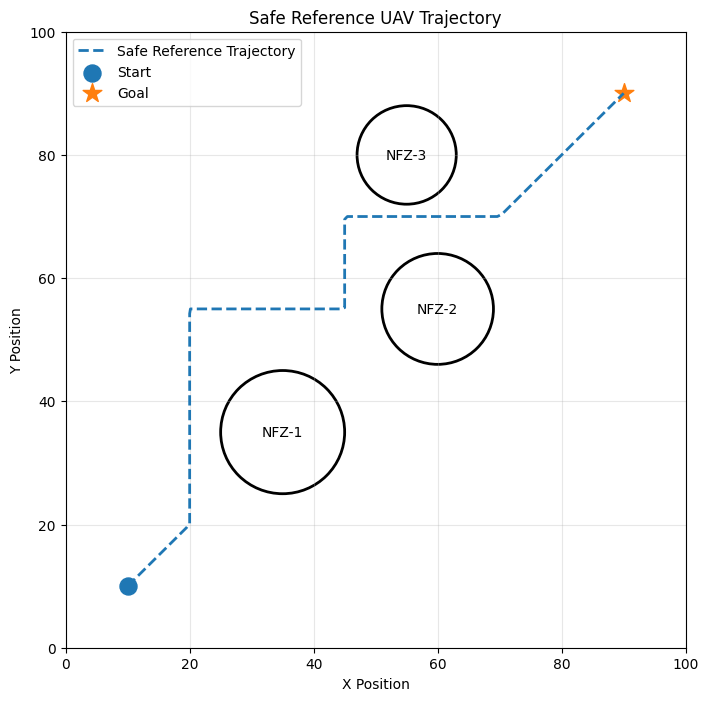

In [7]:
# ============================================================
# FINAL SAFE REFERENCE TRAJECTORY
# ============================================================
reference_path = np.array([reference_point(step) for step in range(MAX_STEPS)])

plt.figure(figsize=(8, 8))
plt.plot(reference_path[:, 0], reference_path[:, 1], "--", linewidth=2, label="Safe Reference Trajectory")
plt.scatter(START[0], START[1], s=150, label="Start")
plt.scatter(GOAL[0], GOAL[1], s=200, marker="*", label="Goal")

for i, (x, y, r) in enumerate(OBSTACLES):
    circle = plt.Circle((x, y), r, fill=False, linewidth=2)
    plt.gca().add_patch(circle)
    plt.text(x, y, f"NFZ-{i+1}", ha="center", va="center")

plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.title("Safe Reference UAV Trajectory")
plt.xlim(0, MAP_SIZE)
plt.ylim(0, MAP_SIZE)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Safe UAV RL Environment

In [8]:

# ============================================================
# FINAL CUSTOM SAFE UAV REINFORCEMENT LEARNING ENVIRONMENT
# ============================================================

class SafeUAVEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self):
        super().__init__()

        # Actions: movement in X, movement in Y, transmit power
        self.action_space = spaces.Box(
            low=np.array([-1.0, -1.0, 0.0], dtype=np.float32),
            high=np.array([1.0, 1.0, 1.0], dtype=np.float32),
            dtype=np.float32
        )

        # 12 observation values
        self.observation_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(12,),
            dtype=np.float32
        )

        self.reset()

    def get_observation(self):
        goal_vector = (GOAL - self.position) / MAP_SIZE
        user_vector = (USER - self.position) / MAP_SIZE

        goal_distance = distance_to_goal(self.position)
        user_distance = distance_to_user(self.position)

        sinr = calculate_sinr(user_distance, self.power)
        comm_fidelity = communication_fidelity(sinr)

        reference = reference_point(self.step_count)
        deviation = float(np.linalg.norm(self.position - reference))
        traj_fidelity = trajectory_fidelity(deviation)

        clearance = minimum_obstacle_clearance(self.position)
        clearance_norm = np.clip(clearance / MAP_SIZE, -1.0, 1.0)

        progress_norm = np.clip(
            (self.previous_goal_distance - goal_distance) / MAX_SPEED,
            -1.0, 1.0
        )

        return np.array([
            goal_vector[0],
            goal_vector[1],
            user_vector[0],
            user_vector[1],
            np.clip(goal_distance / MAP_SIZE, 0.0, 1.0),
            np.clip(user_distance / MAP_SIZE, 0.0, 1.0),
            self.power,
            comm_fidelity,
            np.clip(self.energy / INITIAL_ENERGY, 0.0, 1.0),
            traj_fidelity,
            clearance_norm,
            progress_norm
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.position = START.copy()
        self.power = 0.5
        self.energy = INITIAL_ENERGY
        self.step_count = 0
        self.previous_goal_distance = distance_to_goal(self.position)

        return self.get_observation(), {}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32)
        action = np.clip(
            action,
            self.action_space.low,
            self.action_space.high
        )

        # Calculate movement and transmit power
        movement = action[:2] * MAX_SPEED
        new_power = float(action[2] * MAX_POWER)
        proposed = self.position + movement

        # Detect boundary violations BEFORE clipping
        boundary_violation = bool(
            np.any(proposed < 0.0) or np.any(proposed > MAP_SIZE)
        )

        # Keep the proposed position inside the map
        proposed = np.clip(proposed, 0.0, MAP_SIZE)

        # Check whether the proposed position enters a no-fly zone
        collision = any(
            inside_obstacle(proposed, obstacle, safety_margin=1.5)
            for obstacle in OBSTACLES
        )

        # Reject unsafe movement
        if collision:
            self.position = self.position.copy()
        else:
            self.position = proposed.astype(np.float32)

        self.power = new_power
        self.step_count += 1

        # Communication calculations
        user_distance = distance_to_user(self.position)
        sinr = calculate_sinr(user_distance, self.power)
        comm_fidelity = communication_fidelity(sinr)

        # Trajectory fidelity
        reference = reference_point(self.step_count)
        deviation = float(np.linalg.norm(self.position - reference))
        traj_fidelity = trajectory_fidelity(deviation)

        # Goal progress
        current_goal_distance = distance_to_goal(self.position)
        progress = self.previous_goal_distance - current_goal_distance
        self.previous_goal_distance = current_goal_distance

        # Energy consumption
        actual_movement = float(
            np.linalg.norm(self.position - (self.position - movement))
        )
        movement_energy = 0.025 * float(np.linalg.norm(movement) ** 2)
        communication_energy = 0.03 + 0.06 * self.power
        total_energy = movement_energy + communication_energy
        self.energy = max(0.0, self.energy - total_energy)

        # Reward function: encourage reaching the goal safely
        reward = 12.0 * progress
        reward += 1.5 * comm_fidelity
        reward += 0.8 * traj_fidelity
        reward -= 0.02 * total_energy
        reward -= 0.5 * max(0.0, MIN_SINR_DB - sinr)

        if boundary_violation:
            reward -= 12.0

        if collision:
            reward -= 30.0

        reached_goal = current_goal_distance <= GOAL_TOLERANCE

        if reached_goal:
            reward += 150.0

        # End episode when goal is reached or energy runs out
        terminated = bool(reached_goal or self.energy <= 0.0)
        truncated = bool(self.step_count >= MAX_STEPS)

        info = {
            "goal_distance": float(current_goal_distance),
            "user_distance": float(user_distance),
            "sinr_db": float(sinr),
            "communication_fidelity": float(comm_fidelity),
            "trajectory_fidelity": float(traj_fidelity),
            "trajectory_deviation": float(deviation),
            "energy": float(self.energy),
            "power": float(self.power),
            "collision": bool(collision),
            "boundary_violation": bool(boundary_violation),
            "reached_goal": bool(reached_goal),
            "progress": float(progress)
        }

        return (
            self.get_observation(),
            float(reward),
            terminated,
            truncated,
            info
        )


print("Safe UAV reinforcement learning environment created!")


Safe UAV reinforcement learning environment created!


Environment Validation and Testing

In [9]:
# ============================================================
# CELL 9 — TEST UAV ENVIRONMENT
# ============================================================

env = SafeUAVEnv()

observation, info = env.reset(
    seed=SEED
)

print("Observation shape:")
print(observation.shape)

print("\nInitial observation:")
print(observation)

print("\nAction space:")
print(env.action_space)

print("\nObservation space:")
print(env.observation_space)

Observation shape:
(12,)

Initial observation:
[0.8        0.8        0.65       0.55       1.         0.85146934
 0.5        0.66816217 1.         1.         0.2535534  0.        ]

Action space:
Box([-1. -1.  0.], 1.0, (3,), float32)

Observation space:
Box(-1.0, 1.0, (12,), float32)


UAV action

In [10]:
# ============================================================
# CELL 10 — TEST ONE ACTION
# ============================================================

action = np.array([
    0.5,     # Move in X direction
    0.5,     # Move in Y direction
    0.7      # Communication power
], dtype=np.float32)

observation, reward, terminated, truncated, info = env.step(
    action
)

print("Action:", action)

print("\nReward:", reward)

print("\nUAV position:", env.position)

print("\nGoal distance:",
      round(info["goal_distance"], 2))

print("SINR:",
      round(info["sinr_db"], 2),
      "dB")

print("Communication fidelity:",
      round(info["communication_fidelity"], 3))

print("Trajectory fidelity:",
      round(info["trajectory_fidelity"], 3))

print("Remaining energy:",
      round(info["energy"], 2))

print("Collision:",
      info["collision"])

Action: [0.5 0.5 0.7]

Reward: 23.11533726244163

UAV position: [11.25 11.25]

Goal distance: 111.37
SINR: 8.7 dB
Communication fidelity: 0.774
Trajectory fidelity: 0.93
Remaining energy: 99.85
Collision: False


In [11]:
# Validate the custom Gymnasium environment before training.
env_check = SafeUAVEnv()
check_env(env_check, warn=True)
print("Environment validation completed successfully.")


Environment validation completed successfully.


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


PPO Agent

In [12]:
# ============================================================
# FINAL PPO AGENT
# ============================================================
train_env = SafeUAVEnv()

model = PPO(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    policy_kwargs=dict(net_arch=dict(pi=[128, 128], vf=[128, 128])),
    verbose=1,
    seed=SEED
)

print("PPO agent created successfully!")


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO agent created successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO Training

In [13]:

# ============================================================
# FINAL PPO TRAINING
# ============================================================

train_env = SafeUAVEnv()

model = PPO(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.005,
    vf_coef=0.5,
    max_grad_norm=0.5,
    policy_kwargs=dict(
        net_arch=dict(pi=[128, 128], vf=[128, 128])
    ),
    verbose=1,
    seed=SEED
)

print("PPO agent created successfully!")

# Train the agent
TOTAL_TIMESTEPS = 300_000
model.learn(total_timesteps=TOTAL_TIMESTEPS)

# Save the trained model
model.save("final_safe_uav_ppo")

print("PPO training completed!")
print("Model saved successfully!")



Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO agent created successfully!
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 160       |
|    ep_rew_mean     | -5.13e+03 |
| time/              |           |
|    fps             | 305       |
|    iterations      | 1         |
|    time_elapsed    | 6         |
|    total_timesteps | 2048      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 160         |
|    ep_rew_mean          | -4.78e+03   |
| time/                   |             |
|    fps                  | 287         |
|    iterations           | 2           |
|    time_elapsed         | 14          |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.013221871 |
|    clip_fraction        | 0.194       |
|    clip_range     

Save the trained model

In [14]:
# ============================================================
# CELL 13 — SAVE TRAINED MODEL
# ============================================================

model.save(
    "Fidelity_Aware_Safe_UAV_PPO"
)

print("Model saved successfully!")

Model saved successfully!


Evaluate the trained UAV

In [15]:
# ============================================================
# CELL 14 — EVALUATE TRAINED UAV
# ============================================================

eval_env = SafeUAVEnv()

observation, info = eval_env.reset(
    seed=123
)

total_reward = 0.0

trajectory = [
    eval_env.position.copy()
]

rewards = []
sinrs = []
communication_fidelities = []
trajectory_fidelities = []
energies = []
powers = []
goal_distances = []

for step in range(MAX_STEPS):

    # PPO chooses the action
    action, _ = model.predict(
        observation,
        deterministic=True
    )

    # Execute action
    (
        observation,
        reward,
        terminated,
        truncated,
        info
    ) = eval_env.step(action)

    total_reward += reward

    # Store results
    trajectory.append(
        eval_env.position.copy()
    )

    rewards.append(reward)

    sinrs.append(
        info["sinr_db"]
    )

    communication_fidelities.append(
        info["communication_fidelity"]
    )

    trajectory_fidelities.append(
        info["trajectory_fidelity"]
    )

    energies.append(
        info["energy"]
    )

    powers.append(
        info["power"]
    )

    goal_distances.append(
        info["goal_distance"]
    )

    if terminated or truncated:
        break

trajectory = np.array(trajectory)

print("====================================")
print("      UAV EVALUATION RESULTS")
print("====================================")

print(
    "Total reward:",
    round(total_reward, 2)
)

print(
    "Number of steps:",
    len(rewards)
)

print(
    "Final UAV position:",
    np.round(
        trajectory[-1],
        2
    )
)

print(
    "Final distance to goal:",
    round(
        info["goal_distance"],
        2
    )
)

print(
    "Average SINR:",
    round(
        np.mean(sinrs),
        2
    ),
    "dB"
)

print(
    "Average communication fidelity:",
    round(
        np.mean(communication_fidelities),
        3
    )
)

print(
    "Average trajectory fidelity:",
    round(
        np.mean(trajectory_fidelities),
        3
    )
)

print(
    "Remaining energy:",
    round(
        info["energy"],
        2
    )
)

print(
    "Goal reached:",
    info["reached_goal"]
)

      UAV EVALUATION RESULTS
Total reward: 1518.2
Number of steps: 46
Final UAV position: [85.46 91.71]
Final distance to goal: 4.85
Average SINR: 13.2 dB
Average communication fidelity: 0.933
Average trajectory fidelity: 0.125
Remaining energy: 86.69
Goal reached: True


Plot the learned UAV trajectory

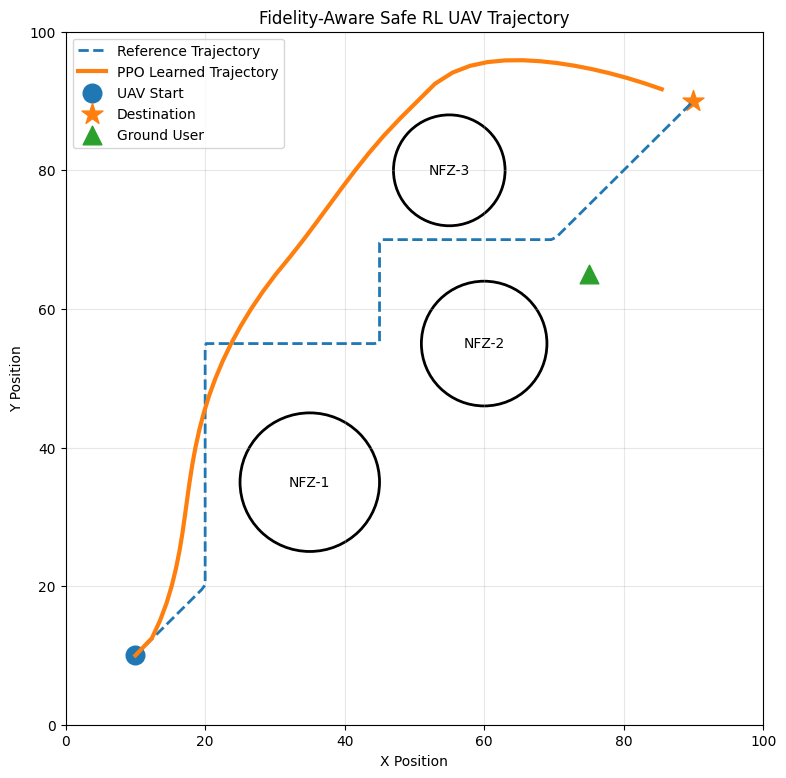

In [16]:
# ============================================================
# CELL 15 — LEARNED UAV TRAJECTORY
# ============================================================

plt.figure(figsize=(9, 9))

# Reference trajectory
plt.plot(
    reference_path[:, 0],
    reference_path[:, 1],
    "--",
    linewidth=2,
    label="Reference Trajectory"
)

# Learned trajectory
plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    linewidth=3,
    label="PPO Learned Trajectory"
)

# Start
plt.scatter(
    START[0],
    START[1],
    s=180,
    marker="o",
    label="UAV Start"
)

# Goal
plt.scatter(
    GOAL[0],
    GOAL[1],
    s=250,
    marker="*",
    label="Destination"
)

# Ground user
plt.scatter(
    USER[0],
    USER[1],
    s=180,
    marker="^",
    label="Ground User"
)

# No-fly zones
for i, (x, y, r) in enumerate(OBSTACLES):

    circle = plt.Circle(
        (x, y),
        r,
        fill=False,
        linewidth=2
    )

    plt.gca().add_patch(circle)

    plt.text(
        x,
        y,
        f"NFZ-{i+1}",
        ha="center",
        va="center"
    )

plt.xlim(0, MAP_SIZE)
plt.ylim(0, MAP_SIZE)

plt.xlabel("X Position")
plt.ylabel("Y Position")

plt.title(
    "Fidelity-Aware Safe RL UAV Trajectory"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

Communication performance

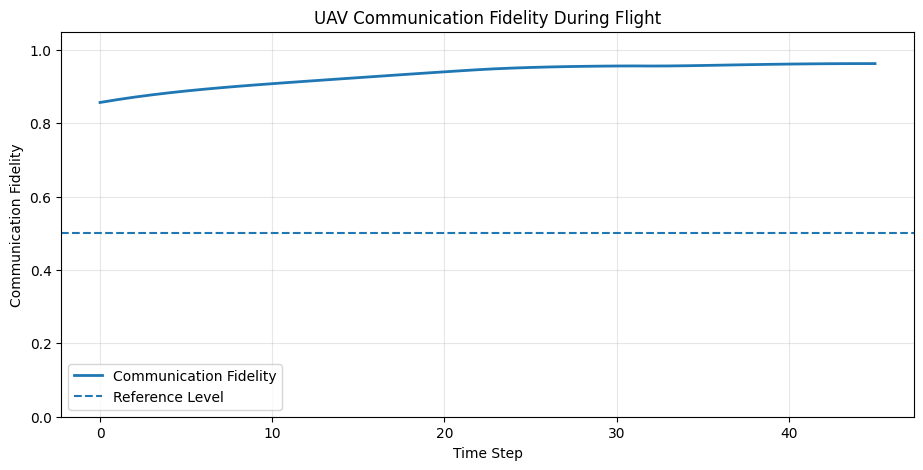

In [17]:
# ============================================================
# CELL 16 — COMMUNICATION FIDELITY
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    communication_fidelities,
    linewidth=2,
    label="Communication Fidelity"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Reference Level"
)

plt.xlabel("Time Step")

plt.ylabel(
    "Communication Fidelity"
)

plt.title(
    "UAV Communication Fidelity During Flight"
)

plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

SINR

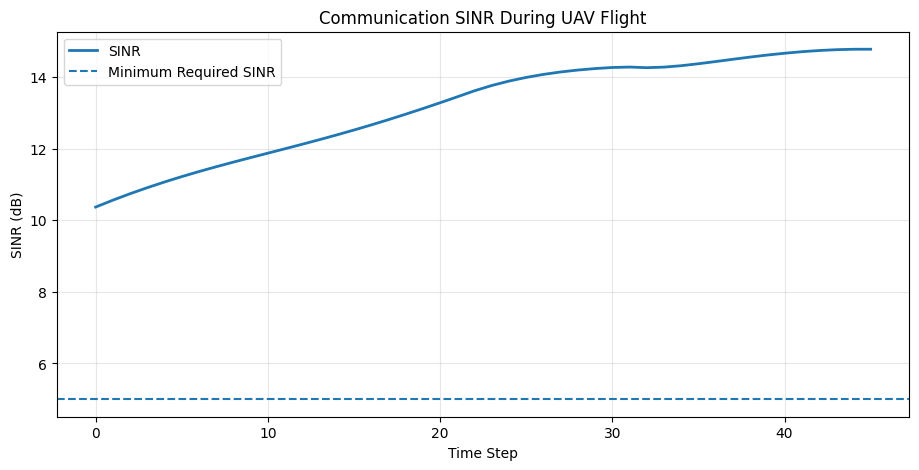

In [18]:
# ============================================================
# CELL 17 — SINR PERFORMANCE
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    sinrs,
    linewidth=2,
    label="SINR"
)

plt.axhline(
    MIN_SINR_DB,
    linestyle="--",
    label="Minimum Required SINR"
)

plt.xlabel("Time Step")

plt.ylabel("SINR (dB)")

plt.title(
    "Communication SINR During UAV Flight"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

Energy consumption

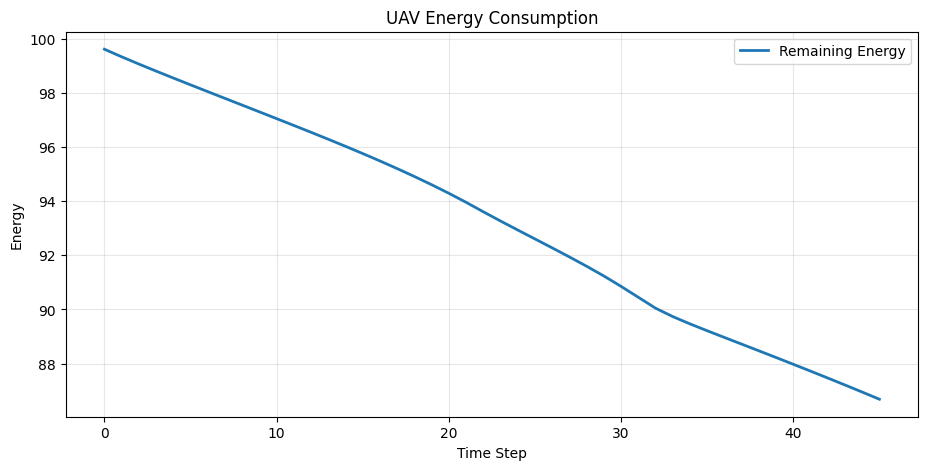

In [19]:
# ============================================================
# CELL 18 — ENERGY CONSUMPTION
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    energies,
    linewidth=2,
    label="Remaining Energy"
)

plt.xlabel("Time Step")

plt.ylabel("Energy")

plt.title(
    "UAV Energy Consumption"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

Communication power control

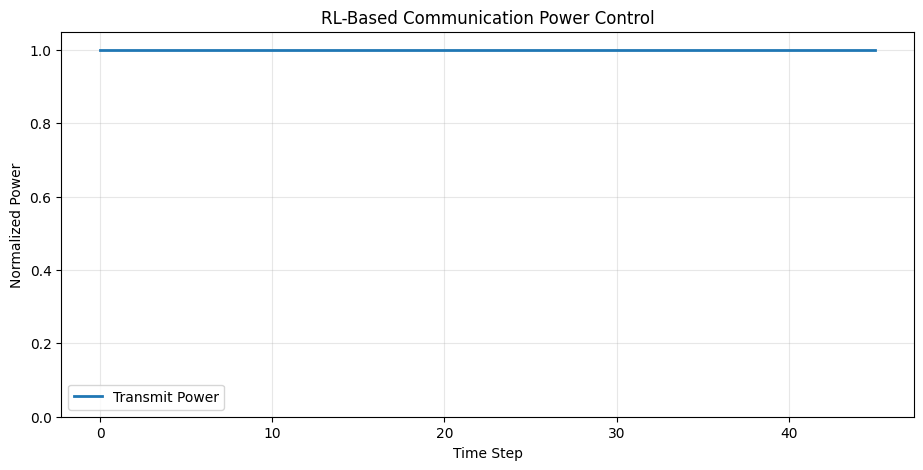

In [20]:
# ============================================================
# CELL 19 — TRANSMIT POWER CONTROL
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    powers,
    linewidth=2,
    label="Transmit Power"
)

plt.xlabel("Time Step")

plt.ylabel("Normalized Power")

plt.title(
    "RL-Based Communication Power Control"
)

plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

Greedy baseline

In [21]:
# ============================================================
# CELL 20 — GREEDY UAV BASELINE
# ============================================================

def run_greedy_episode(seed=0):

    env = SafeUAVEnv()

    observation, info = env.reset(
        seed=seed
    )

    total_reward = 0.0
    infos = []

    for step in range(MAX_STEPS):

        # Direction directly toward destination
        direction = GOAL - env.position

        distance = np.linalg.norm(direction)

        direction = direction / (
            distance + 1e-8
        )

        # Greedy controller:
        # always move toward the goal
        #
        # Communication power is fixed
        action = np.array([
            direction[0],
            direction[1],
            0.65
        ], dtype=np.float32)

        (
            observation,
            reward,
            terminated,
            truncated,
            info
        ) = env.step(action)

        total_reward += reward

        infos.append(info)

        if terminated or truncated:
            break

    return total_reward, infos


print("Testing greedy baseline...")

greedy_reward, greedy_infos = run_greedy_episode(
    seed=100
)

print("Greedy total reward:",
      round(greedy_reward, 2))

print("Greedy final distance:",
      round(
          greedy_infos[-1]["goal_distance"],
          2
      ))

print("Greedy average SINR:",
      round(
          np.mean([
              x["sinr_db"]
              for x in greedy_infos
          ]),
          2
      ),
      "dB")

print("Greedy communication fidelity:",
      round(
          np.mean([
              x["communication_fidelity"]
              for x in greedy_infos
          ]),
          3
      ))

print("Greedy collisions:",
      sum(
          x["collision"]
          for x in greedy_infos
      ))

Testing greedy baseline...
Greedy total reward: -4039.53
Greedy final distance: 90.64
Greedy average SINR: 10.0 dB
Greedy communication fidelity: 0.841
Greedy collisions: 151


Evaluate PPO over multiple episodes

In [22]:
# ============================================================
# CELL 21 — MULTI-EPISODE PPO EVALUATION
# ============================================================

N_EVAL_EPISODES = 20

ppo_results = []

for episode in range(N_EVAL_EPISODES):

    env = SafeUAVEnv()

    observation, info = env.reset(
        seed=1000 + episode
    )

    total_reward = 0.0
    infos = []

    for step in range(MAX_STEPS):

        action, _ = model.predict(
            observation,
            deterministic=True
        )

        (
            observation,
            reward,
            terminated,
            truncated,
            info
        ) = env.step(action)

        total_reward += reward

        infos.append(info)

        if terminated or truncated:
            break

    ppo_results.append({

        "Episode":
            episode + 1,

        "Reward":
            total_reward,

        "Goal Distance":
            infos[-1]["goal_distance"],

        "Average SINR":
            np.mean([
                x["sinr_db"]
                for x in infos
            ]),

        "Communication Fidelity":
            np.mean([
                x["communication_fidelity"]
                for x in infos
            ]),

        "Trajectory Fidelity":
            np.mean([
                x["trajectory_fidelity"]
                for x in infos
            ]),

        "Final Energy":
            infos[-1]["energy"],

        "Collisions":
            sum(
                x["collision"]
                for x in infos
            ),

        "Boundary Violations":
            sum(
                x["boundary_violation"]
                for x in infos
            ),

        "Goal Reached":
            infos[-1]["reached_goal"]

    })


ppo_df = pd.DataFrame(
    ppo_results
)

display(ppo_df)

,Episode,Reward,Goal Distance,Average SINR,Communication Fidelity,Trajectory Fidelity,Final Energy,Collisions,Boundary Violations,Goal Reached
0,1,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
1,2,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
2,3,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
3,4,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
4,5,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
5,6,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
6,7,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
7,8,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
8,9,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True
9,10,1518.203496,4.848539,13.196455,0.933268,0.125319,86.685367,0,0,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Final PPO performance

In [23]:
# ============================================================
# CELL 22 — PPO PERFORMANCE SUMMARY
# ============================================================

print("============================================")
print("       PPO PERFORMANCE SUMMARY")
print("============================================")

print(
    "Average Reward:",
    round(
        ppo_df["Reward"].mean(),
        2
    )
)

print(
    "Goal Success Rate:",
    round(
        ppo_df["Goal Reached"].mean() * 100,
        2
    ),
    "%"
)

print(
    "Average Final Goal Distance:",
    round(
        ppo_df["Goal Distance"].mean(),
        2
    )
)

print(
    "Average SINR:",
    round(
        ppo_df["Average SINR"].mean(),
        2
    ),
    "dB"
)

print(
    "Average Communication Fidelity:",
    round(
        ppo_df["Communication Fidelity"].mean(),
        3
    )
)

print(
    "Average Trajectory Fidelity:",
    round(
        ppo_df["Trajectory Fidelity"].mean(),
        3
    )
)

print(
    "Average Final Energy:",
    round(
        ppo_df["Final Energy"].mean(),
        2
    )
)

print(
    "Average Collisions:",
    round(
        ppo_df["Collisions"].mean(),
        2
    )
)

print(
    "Average Boundary Violations:",
    round(
        ppo_df["Boundary Violations"].mean(),
        2
    )
)

       PPO PERFORMANCE SUMMARY
Average Reward: 1518.2
Goal Success Rate: 100.0 %
Average Final Goal Distance: 4.85
Average SINR: 13.2 dB
Average Communication Fidelity: 0.933
Average Trajectory Fidelity: 0.125
Average Final Energy: 86.69
Average Collisions: 0.0
Average Boundary Violations: 0.0


Compare PPO vs Greedy

In [24]:
# ============================================================
# CELL 23 — PPO VS GREEDY COMPARISON
# ============================================================

# Run greedy for the same number of episodes

greedy_results = []

for episode in range(N_EVAL_EPISODES):

    reward, infos = run_greedy_episode(
        seed=1000 + episode
    )

    greedy_results.append({

        "Reward":
            reward,

        "Goal Distance":
            infos[-1]["goal_distance"],

        "Average SINR":
            np.mean([
                x["sinr_db"]
                for x in infos
            ]),

        "Communication Fidelity":
            np.mean([
                x["communication_fidelity"]
                for x in infos
            ]),

        "Trajectory Fidelity":
            np.mean([
                x["trajectory_fidelity"]
                for x in infos
            ]),

        "Final Energy":
            infos[-1]["energy"],

        "Collisions":
            sum(
                x["collision"]
                for x in infos
            ),

        "Goal Reached":
            infos[-1]["reached_goal"]

    })


greedy_df = pd.DataFrame(
    greedy_results
)


comparison = pd.DataFrame({

    "Metric": [

        "Average Reward",

        "Goal Success Rate (%)",

        "Average Goal Distance",

        "Average SINR (dB)",

        "Communication Fidelity",

        "Trajectory Fidelity",

        "Final Energy",

        "Average Collisions"

    ],

    "PPO": [

        ppo_df["Reward"].mean(),

        ppo_df["Goal Reached"].mean() * 100,

        ppo_df["Goal Distance"].mean(),

        ppo_df["Average SINR"].mean(),

        ppo_df["Communication Fidelity"].mean(),

        ppo_df["Trajectory Fidelity"].mean(),

        ppo_df["Final Energy"].mean(),

        ppo_df["Collisions"].mean()

    ],

    "Greedy": [

        greedy_df["Reward"].mean(),

        greedy_df["Goal Reached"].mean() * 100,

        greedy_df["Goal Distance"].mean(),

        greedy_df["Average SINR"].mean(),

        greedy_df["Communication Fidelity"].mean(),

        greedy_df["Trajectory Fidelity"].mean(),

        greedy_df["Final Energy"].mean(),

        greedy_df["Collisions"].mean()

    ]

})


display(comparison)

,Metric,PPO,Greedy
0,Average Reward,1518.203496,-4039.529989
1,Goal Success Rate (%),100.000000,0.000000
2,Average Goal Distance,4.848539,90.637085
3,Average SINR (dB),13.196455,9.995742
4,Communication Fidelity,0.933268,0.840677
5,Trajectory Fidelity,0.125319,0.151784
6,Final Energy,86.685367,63.960000
7,Average Collisions,0.000000,151.000000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Visual comparison

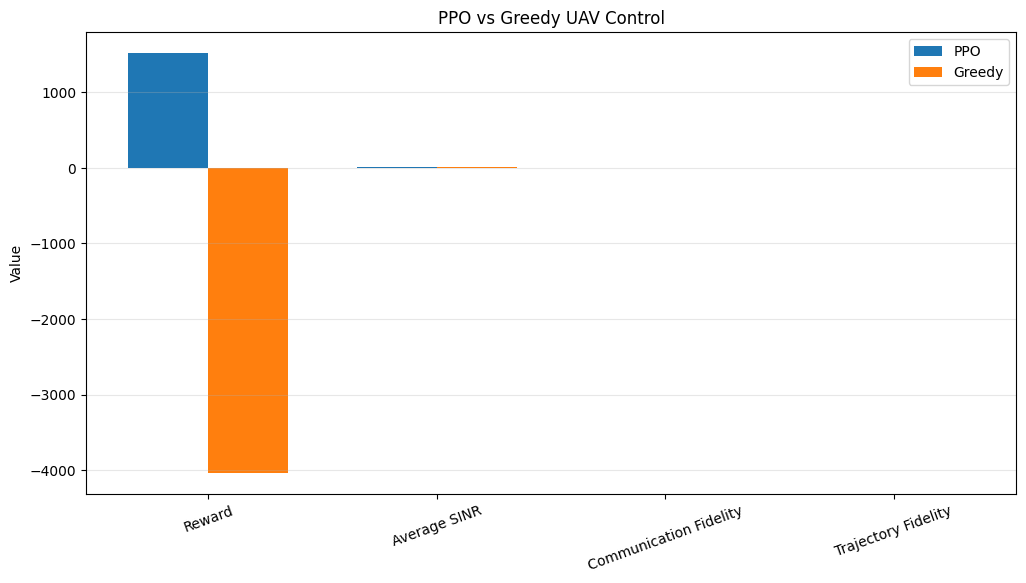

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
# ============================================================
# CELL 24 — VISUAL PERFORMANCE COMPARISON
# ============================================================

metrics = [
    "Reward",
    "Average SINR",
    "Communication Fidelity",
    "Trajectory Fidelity"
]

ppo_values = [
    ppo_df["Reward"].mean(),
    ppo_df["Average SINR"].mean(),
    ppo_df["Communication Fidelity"].mean(),
    ppo_df["Trajectory Fidelity"].mean()
]

greedy_values = [
    greedy_df["Reward"].mean(),
    greedy_df["Average SINR"].mean(),
    greedy_df["Communication Fidelity"].mean(),
    greedy_df["Trajectory Fidelity"].mean()
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    ppo_values,
    width,
    label="PPO"
)

plt.bar(
    x + width/2,
    greedy_values,
    width,
    label="Greedy"
)

plt.xticks(
    x,
    metrics,
    rotation=20
)

plt.ylabel("Value")

plt.title(
    "PPO vs Greedy UAV Control"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [26]:
# ============================================================
#CELL-25 LIVE UAV SIMULATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Create evaluation environment
sim_env = SafeUAVEnv()

observation, info = sim_env.reset(seed=123)

# Store UAV positions
sim_positions = [sim_env.position.copy()]

# Store live information
sim_rewards = []
sim_sinr = []
sim_energy = []
sim_distance = []

# Run trained PPO
for step in range(MAX_STEPS):

    # PPO chooses the UAV action
    action, _ = model.predict(
        observation,
        deterministic=True
    )

    # Execute action
    (
        observation,
        reward,
        terminated,
        truncated,
        info
    ) = sim_env.step(action)

    # Store position
    sim_positions.append(
        sim_env.position.copy()
    )

    # Store information
    sim_rewards.append(reward)
    sim_sinr.append(info["sinr_db"])
    sim_energy.append(info["energy"])
    sim_distance.append(info["goal_distance"])

    if terminated or truncated:
        break

sim_positions = np.array(sim_positions)

print("Simulation steps:", len(sim_positions))
print("Final position:", sim_positions[-1])
print("Final distance:", sim_distance[-1])

Simulation steps: 47
Final position: [85.46211 91.7076 ]
Final distance: 4.848539352416992


In [27]:
# ============================================================
#  CELL-26 COMPLETE LIVE UAV ANIMATION + RESULTS CHECK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


# ============================================================
# PART 1 — CHECK THE PPO TRAJECTORY
# ============================================================

print("==============================================")
print("        UAV PPO SIMULATION CHECK")
print("==============================================")

print("Number of trajectory points:", len(trajectory))
print("MAX_STEPS:", MAX_STEPS)

print("Last position:", trajectory[-1])

print("Last distance:", goal_distances[-1])

print("Last energy:", energies[-1])

print(
    "Goal reached:",
    goal_distances[-1] <= GOAL_TOLERANCE
)

print("==============================================")


# ============================================================
# PART 2 — PREPARE TRAJECTORY
# ============================================================

trajectory = np.array(trajectory)

# Number of frames
num_frames = len(trajectory)


# ============================================================
# PART 3 — CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

ax.set_xlim(0, MAP_SIZE)
ax.set_ylim(0, MAP_SIZE)

ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")

ax.set_title(
    "Fidelity-Aware Safe Reinforcement Learning UAV"
)

ax.grid(True, alpha=0.3)


# ============================================================
# PART 4 — START POINT
# ============================================================

ax.scatter(
    START[0],
    START[1],
    s=180,
    marker="o",
    label="UAV Start"
)

ax.text(
    START[0] + 2,
    START[1] + 2,
    "START",
    fontsize=10
)


# ============================================================
# PART 5 — DESTINATION
# ============================================================

ax.scatter(
    GOAL[0],
    GOAL[1],
    s=280,
    marker="*",
    label="Destination"
)

ax.text(
    GOAL[0] - 8,
    GOAL[1] - 6,
    "GOAL",
    fontsize=10
)


# ============================================================
# PART 6 — GROUND USER
# ============================================================

ax.scatter(
    USER[0],
    USER[1],
    s=180,
    marker="^",
    label="Ground User"
)

ax.text(
    USER[0] + 2,
    USER[1] + 2,
    "Ground User",
    fontsize=10
)


# ============================================================
# PART 7 — NO-FLY ZONES
# ============================================================

for i, (x, y, r) in enumerate(OBSTACLES):

    circle = plt.Circle(
        (x, y),
        r,
        fill=False,
        linewidth=3
    )

    ax.add_patch(circle)

    ax.text(
        x,
        y,
        f"NFZ-{i+1}",
        ha="center",
        va="center",
        fontsize=10
    )


# ============================================================
# PART 8 — UAV TRAJECTORY LINE
# ============================================================

path_line, = ax.plot(
    [],
    [],
    linewidth=2,
    label="PPO UAV Trajectory"
)


# ============================================================
# PART 9 — UAV MARKER
# ============================================================

uav, = ax.plot(
    [],
    [],
    marker="o",
    markersize=12,
    linestyle="None",
    label="UAV"
)


# ============================================================
# PART 10 — LIVE INFORMATION BOX
# ============================================================

info_text = ax.text(
    0.02,
    0.97,
    "",
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=10
)


# ============================================================
# PART 11 — LEGEND
# ============================================================

ax.legend(
    loc="lower right"
)


# ============================================================
# PART 12 — ANIMATION UPDATE FUNCTION
# ============================================================

def update(frame):

    # --------------------------------------------
    # Current UAV position
    # --------------------------------------------

    x = trajectory[frame, 0]
    y = trajectory[frame, 1]


    # --------------------------------------------
    # Move UAV marker
    # --------------------------------------------

    uav.set_data(
        [x],
        [y]
    )


    # --------------------------------------------
    # Draw trajectory travelled so far
    # --------------------------------------------

    path_line.set_data(
        trajectory[:frame + 1, 0],
        trajectory[:frame + 1, 1]
    )


    # --------------------------------------------
    # Get current metrics
    # --------------------------------------------

    if frame > 0:

        metric_index = frame - 1

        if metric_index < len(sinrs):
            current_sinr = sinrs[metric_index]
        else:
            current_sinr = sinrs[-1]

        if metric_index < len(energies):
            current_energy = energies[metric_index]
        else:
            current_energy = energies[-1]

        if metric_index < len(goal_distances):
            current_distance = goal_distances[metric_index]
        else:
            current_distance = goal_distances[-1]

        if metric_index < len(communication_fidelities):
            current_comm = communication_fidelities[metric_index]
        else:
            current_comm = communication_fidelities[-1]

    else:

        current_sinr = sinrs[0]
        current_energy = energies[0]
        current_distance = goal_distances[0]
        current_comm = communication_fidelities[0]


    # --------------------------------------------
    # Determine UAV status
    # --------------------------------------------

    if current_distance <= GOAL_TOLERANCE:

        status = "GOAL REACHED"

    elif current_energy <= 0:

        status = "ENERGY DEPLETED"

    else:

        status = "UAV FLYING"


    # --------------------------------------------
    # Update information box
    # --------------------------------------------

    info_text.set_text(
        f"Step: {frame + 1}\n"
        f"UAV Position: ({x:.2f}, {y:.2f})\n"
        f"Distance to Goal: {current_distance:.2f}\n"
        f"SINR: {current_sinr:.2f} dB\n"
        f"Communication Fidelity: {current_comm:.3f}\n"
        f"Energy: {current_energy:.2f}\n"
        f"Status: {status}"
    )


    return (
        uav,
        path_line,
        info_text
    )


# ============================================================
# PART 13 — CREATE ANIMATION
# ============================================================

animation = FuncAnimation(
    fig,
    update,
    frames=num_frames,
    interval=150,
    blit=True,
    repeat=False
)


# Prevent duplicate static figure
plt.close(fig)


# ============================================================
# PART 14 — DISPLAY ANIMATION
# ============================================================

display(
    HTML(
        animation.to_jshtml()
    )
)

        UAV PPO SIMULATION CHECK
Number of trajectory points: 47
MAX_STEPS: 160
Last position: [85.46211 91.7076 ]
Last distance: 4.848539352416992
Last energy: 86.68536728382112
Goal reached: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
